# 
 Notebook 3 — All-India Demand Forecasting (1 to 14 days ahead)
### Weather-Aware Peak-Demand Management System — national version

**Why this notebook?** Notebooks 1–2 used Northern Region data that stops in April 2024, so the app could only *replay* history.
Public, regularly-updated demand data exists only for **all of India** (Grid-India's daily reports, converted to CSV by the Grid-Sentinel project). Switching to all-India lets the app forecast **today and the coming days**.

**What's new here**
1. **National demand**, 2019 → Sept 2026, from two sources stitched together (and checked for consistency).
2. **Weather from 11 cities across India**, grouped by region (north, west, south, east).
3. **14 models, one per horizon.** If the newest demand data is *h* days old, the model for horizon *h* is used. Fresh data → most accurate model; stale data → still works, a bit less accurate.

| Input | File | Period |
|---|---|---|
| National hourly demand (old) | `study1_hourly.csv` | Jan 2019 → Apr 2024 |
| National 15-min demand (new, auto-updated daily) | `study2_scada.csv` (downloaded from GitHub) | Nov 2024 → latest |
| Weather, 11 cities | `era5_weather_india_hourly.csv` + `era5_weather_india_2024_2026.csv` | Jan 2019 → Oct 2026 |

## 0. Setup & configuration

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sklearn, xgboost

C = {"blue": "#465fff", "orange": "#eb6834", "green": "#12a873", "red": "#d03b3b", "amber": "#f5a50b", "grey": "#8a8984", "ink": "#101828"}
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "lines.linewidth": 1.6})

#  CHANGE THIS if your files live elsewhere
OLD_DEMAND_FILE = "study1_hourly.csv"
NEW_DEMAND_FILE = "study2_scada.csv"
NEW_DEMAND_URL  = "https://raw.githubusercontent.com/HalcyonVector/Grid-Sentinel/main/Dataset/study2_scada.csv"
WEATHER_FILES   = ["era5_weather_india_hourly.csv", "era5_weather_india_2024_2026.csv"]
OUT_DIR         = "national"          # models + config for the backend are saved here

TEST_MONTHS = 12                      # the last 12 months of data are the unseen test period
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1


# PART 1 — National demand data

## 1.1 Load both sources

- **Old file:** already hourly, column `National Hourly Demand`.
- **New file:** one row per **15-minute block** (96 per day), column `demand_met_mw`. It's ~70 MB and grows daily, so it's downloaded from GitHub if not present.

The Grid-Sentinel README tells us three days are corrupted (1–63 blocks instead of 96); we drop them. Then we average the four 15-minute blocks of each hour into **one hourly value**, keeping only hours with at least 3 of the 4 blocks.

In [2]:
old = pd.read_csv(OLD_DEMAND_FILE, usecols=["datetime", "National Hourly Demand"], parse_dates=["datetime"])
old = old.rename(columns={"National Hourly Demand": "demand"}).set_index("datetime").sort_index()["demand"]

src = NEW_DEMAND_FILE if os.path.exists(NEW_DEMAND_FILE) else NEW_DEMAND_URL
new = pd.read_csv(src, usecols=["date", "time", "demand_met_mw"], low_memory=False)
new["ts"] = pd.to_datetime(new["date"] + " " + new["time"])
blocks = new.groupby("date").size()
print("Days by number of 15-min blocks:", blocks.value_counts().to_dict())

BAD_DAYS = ["2024-11-20", "2025-04-01", "2025-10-02"]          # documented as corrupted
new = new[~new["date"].isin(BAD_DAYS)].drop_duplicates("ts")
hourly = new.set_index("ts")["demand_met_mw"].resample("h").agg(["mean", "count"])
new_h = hourly.loc[hourly["count"] >= 3, "mean"].rename("demand")

print(f"Old: {old.index.min()} → {old.index.max()}  ({len(old):,} hours)")
print(f"New: {new_h.index.min()} → {new_h.index.max()}  ({len(new_h):,} hours)")

Days by number of 15-min blocks: {96: 670, 95: 5, 1: 2, 63: 1}
Old: 2019-01-01 00:00:00 → 2024-04-30 23:00:00  (46,728 hours)
New: 2024-11-04 00:00:00 → 2026-09-29 23:00:00  (16,200 hours)


## 1.2  Can we safely join them? (consistency check)

Two different sources could measure demand slightly differently. If they did, the model would see a fake "jump" where they meet. We check:
1. **Monthly averages** should keep growing smoothly year after year (India's demand grows ~4–6% per year).
2. **The daily shape** (average demand per hour) should look the same in both.

In [3]:
m_old = old.resample("MS").mean() / 1000
m_new = new_h.resample("MS").mean() / 1000
table = pd.DataFrame({mon: {y: round(v, 1) for y, v in pd.concat([m_old, m_new]).groupby(lambda t: t.year)
                            .apply(lambda s: s[s.index.month == mon].mean() if (s.index.month == mon).any() else np.nan).items()}
                      for mon in [11, 12, 1, 2, 3, 4]})
table.columns = ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"]
print("Average demand (GW) by month and year — old source ≤ Apr 2024, new source ≥ Nov 2024:")
display(table)

prof_old = old[old.index.month == 12].groupby(old[old.index.month == 12].index.hour).mean()
prof_new = new_h[new_h.index.month == 12].groupby(new_h[new_h.index.month == 12].index.hour).mean()
print(f"December daily-shape correlation between sources: {np.corrcoef(prof_old, prof_new)[0, 1]:.3f}")

Average demand (GW) by month and year — old source ≤ Apr 2024, new source ≥ Nov 2024:


,Nov,Dec,Jan,Feb,Mar,Apr
2019,130.6,135.8,138.0,140.5,147.1,154.3
2020,135.4,143.6,141.4,149.5,134.0,116.5
2021,138.5,147.5,149.5,155.5,164.3,164.7
2022,155.8,161.8,150.4,162.3,174.4,183.5
2023,165.9,165.0,168.6,174.3,171.3,181.3
2024,174.5,175.4,179.3,183.0,186.5,186.4
2025,171.5,186.6,185.0,196.0,199.4,204.4
2026,NaN,NaN,192.7,198.6,201.0,214.0


December daily-shape correlation between sources: 0.997


**Verdict:** the growth continues smoothly across the join (no jump), and the daily shapes are almost identical → safe to combine.

## 1.3 Combine into one hourly series

We put both on a single, complete hourly timeline. The **May–Oct 2024 gap** (between the sources) and a few missing days become `NaN`. We do **not** fill a 6-month gap — that would invent data. Rows whose features need missing hours are simply skipped during training.

Timeline: 2019-01-01 00:00:00 → 2026-09-29 23:00:00 | known hours: 62,928 | missing: 4,968


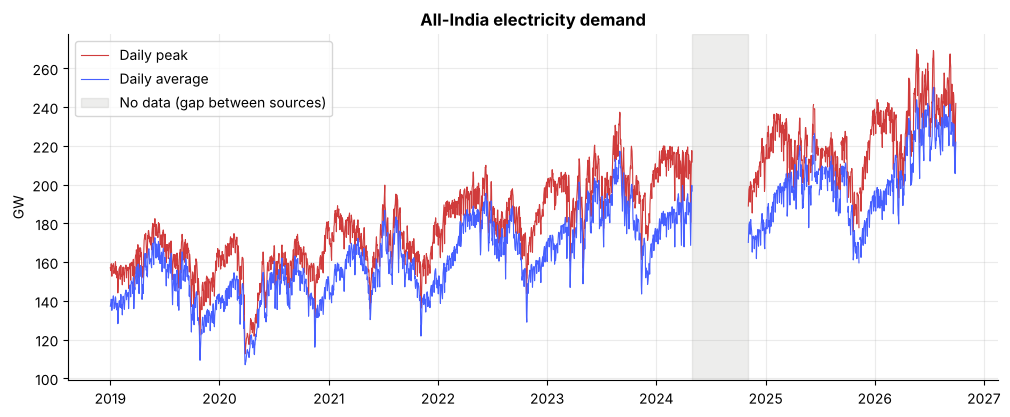

Yearly peak (GW): {2019: 182.4, 2020: 180.9, 2021: 199.7, 2022: 209.9, 2023: 237.4, 2024: 223.9, 2025: 241.3, 2026: 269.6}


In [4]:
demand = pd.concat([old, new_h]).sort_index()
demand = demand[~demand.index.duplicated()]
demand = demand.reindex(pd.date_range(demand.index.min(), demand.index.max(), freq="h"))
print(f"Timeline: {demand.index.min()} → {demand.index.max()} | known hours: {demand.notna().sum():,} | missing: {demand.isna().sum():,}")

daily = demand.resample("D").agg(["mean", "max"]) / 1000
fig, ax = plt.subplots()
ax.plot(daily.index, daily["max"], color=C["red"], lw=0.8, label="Daily peak")
ax.plot(daily.index, daily["mean"], color=C["blue"], lw=0.8, label="Daily average")
ax.axvspan(pd.Timestamp("2024-05-01"), pd.Timestamp("2024-11-04"), color=C["grey"], alpha=0.15, label="No data (gap between sources)")
ax.set_title("All-India electricity demand"); ax.set_ylabel("GW"); ax.legend(loc="upper left"); plt.show()
print("Yearly peak (GW):", (demand.groupby(demand.index.year).max() / 1000).round(1).to_dict())

# PART 2 — Weather for all of India

National demand reacts to heat in **every** region, and regions peak at different times of year (north: May–June heat; south: March–May; monsoon cools the west from June). So instead of one city, we use **11 cities in 4 regional groups**:

- **National averages**: temperature, humidity, feels-like, rain, and average cooling/heating need (computed *per city first*, then averaged — a heatwave in Delhi still counts even if Bengaluru is mild).
- **Regional feels-like**: north, west, south, east.

The same function will later turn **live weather-forecast data** into exactly the same columns.

In [5]:
# 11 cities, grouped by grid region. National demand reacts to heat in every region.
CITY_GROUPS = {
    "north": ["delhi", "lucknow", "jaipur", "chandigarh", "ludhiana"],
    "west": ["mumbai", "ahmedabad"],
    "south": ["chennai", "bengaluru", "hyderabad"],
    "east": ["kolkata"],
}
CITIES = [c for group in CITY_GROUPS.values() for c in group]
CDH_BASE, HDH_BASE = 24.0, 18.0


def aggregate_weather(long_df):
    """Turn per-city hourly weather (long format, Open-Meteo column names) into one
    row per hour with national averages + regional 'feels like' temperatures."""
    w = long_df.rename(columns={"temperature_2m": "temperature", "relative_humidity_2m": "humidity",
                                "apparent_temperature": "feels_like", "precipitation": "rain_mm"}).copy()
    w["datetime"] = pd.to_datetime(w["datetime"], format="ISO8601")
    w = w[w["city"].isin(CITIES)]
    w["cdh_city"] = (w["feels_like"] - CDH_BASE).clip(lower=0)     # cooling need per city
    w["hdh_city"] = (HDH_BASE - w["temperature"]).clip(lower=0)    # heating need per city

    nat = w.groupby("datetime")[["temperature", "humidity", "feels_like", "rain_mm", "cdh_city", "hdh_city"]].mean()
    nat.columns = ["nat_temp", "nat_humidity", "nat_feels", "nat_rain", "nat_cdh", "nat_hdh"]
    for region, cities in CITY_GROUPS.items():
        nat[f"feels_{region}"] = w[w["city"].isin(cities)].groupby("datetime")["feels_like"].mean()
    complete = w.groupby("datetime")["city"].nunique() == len(CITIES)  # only hours with all 11 cities
    return nat[complete.reindex(nat.index, fill_value=False)]


WEATHER_FEATURES = ["nat_temp", "nat_humidity", "nat_feels", "nat_rain", "nat_cdh", "nat_hdh",
                    "feels_north", "feels_west", "feels_south", "feels_east"]

In [6]:
weather_long = pd.concat([pd.read_csv(f) for f in WEATHER_FILES], ignore_index=True)
weather = aggregate_weather(weather_long)
print(f"Weather: {weather.index.min()} → {weather.index.max()} ({len(weather):,} hours)")
data = weather.join(demand.rename("demand"), how="left")
data = data[data.index <= demand.index.max()]
print("Correlation of national demand with:")
print(data[["demand"] + WEATHER_FEATURES].corr()["demand"].drop("demand").sort_values(ascending=False).round(3))

Weather: 2019-01-01 00:00:00 → 2026-10-03 23:00:00 (67,992 hours)
Correlation of national demand with:
nat_temp        0.377
nat_feels       0.365
feels_north     0.361
nat_cdh         0.354
feels_west      0.330
feels_east      0.330
feels_south     0.319
nat_rain        0.030
nat_humidity   -0.246
nat_hdh        -0.284
Name: demand, dtype: float64


# PART 3 — Features for 14 horizons

**The idea.** Live demand data can be 1 day old (best case) or up to ~2 weeks old (if the public data source lags). We train **one model per horizon *h* = 1…14 days**:

- For horizon *h*, the newest demand the model may use is **h days before** the hour being forecast.
- **Lags:** demand *h* days ago, *h*+1 days ago, and the same weekday 1–2 weeks back (`lag_168`, `lag_336`…).
- **Anchor:** each model predicts the **change** from an anchor value (lesson from Notebook 1: this lets it reach new record highs):
  - *h* = 1 → change vs **yesterday, same hour** (`lag_24`)
  - *h* ≥ 2 → change vs **same weekday, same hour, 1 or 2 weeks back** (weekly patterns matter more than "4 days ago")
- **Model size:** *h* ≤ 2 uses a deeper XGBoost; longer horizons use a **simpler** one — when the newest data is far away, a complex model mostly memorises noise.

Plus calendar features (now also *day of year*), the weather at the target hour, and **how much hotter it is now** than on the anchor day.

In [7]:
SEASON_MAP = {12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 2, 10: 3, 11: 3}
CALENDAR_FEATURES = ["hour", "day_of_week", "month", "is_weekend", "season",
                     "hour_sin", "hour_cos", "doy_sin", "doy_cos"]
HORIZONS = range(1, 15)         # 1 to 14 days after the newest demand data


def week_lag(h):
    """Smallest whole number of weeks (in hours) that is at least h days back."""
    return 168 * int(np.ceil(h / 7))


def lag_hours(h):
    """Demand lags allowed for horizon h: nothing newer than h*24 hours before the target hour."""
    L, wk = 24 * h, week_lag(h)
    return sorted({L, L + 24, wk, wk + 168})


def base_col(h):
    """The model predicts the CHANGE from this lag (1 day ahead: yesterday; otherwise same weekday)."""
    return "lag_24" if h == 1 else f"lag_{week_lag(h)}"


def model_params(h):
    """Short horizons: a deeper model. Longer horizons: a simpler model that overfits less."""
    if h <= 2:
        return dict(n_estimators=600, learning_rate=0.05, max_depth=6, min_child_weight=1)
    return dict(n_estimators=200, learning_rate=0.05, max_depth=3, min_child_weight=50)


def feature_names(h):
    return CALENDAR_FEATURES + WEATHER_FEATURES + ["feels_change", "feels_change_wk",
            "roll_mean_24", "roll_max_24", "roll_mean_168"] + [f"lag_{k}" for k in lag_hours(h)]


def make_features(d, h):
    """d: hourly DataFrame (datetime index) with 'demand' + WEATHER_FEATURES.
    Returns d with every feature for horizon h. Nothing uses demand newer than t - 24h."""
    d = d.copy()
    idx = d.index
    L, wk = 24 * h, week_lag(h)
    d["hour"] = idx.hour
    d["day_of_week"] = idx.dayofweek
    d["month"] = idx.month
    d["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    d["season"] = d["month"].map(SEASON_MAP)
    d["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    d["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    d["doy_sin"] = np.sin(2 * np.pi * idx.dayofyear / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * idx.dayofyear / 365.25)

    for k in lag_hours(h):
        d[f"lag_{k}"] = d["demand"].shift(k)
    past = d["demand"].shift(L)                       # newest demand value we may use
    d["roll_mean_24"] = past.rolling(24).mean()
    d["roll_max_24"] = past.rolling(24).max()
    d["roll_mean_168"] = past.rolling(168).mean()
    d["feels_change"] = d["nat_feels"] - d["nat_feels"].shift(L)       # hotter/colder than then?
    d["feels_change_wk"] = d["nat_feels"] - d["nat_feels"].shift(wk)
    return d

# PART 4 — Train and test every horizon

**Chronological split:** the last 12 months are the **test year**; the model never sees them. We compare each horizon with the simplest honest baseline: *"copy the same hour from the same weekday 1 (or 2) weeks ago."*

In [8]:
last = data["demand"].last_valid_index()
TEST_START = (last - pd.DateOffset(months=TEST_MONTHS)).normalize() + pd.Timedelta(days=1)
print(f"Train: up to {TEST_START.date()} (exclusive) | Test: {TEST_START.date()} → {last.date()}")

def make_model(h):
    return XGBRegressor(subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, **model_params(h))

rows, backtest_models, test_preds = [], {}, {}
t0 = time.time()
for h in HORIZONS:
    F, base = feature_names(h), base_col(h)
    table_h = make_features(data, h)[F + ["demand"]].dropna()
    tr, te = table_h[table_h.index < TEST_START], table_h[table_h.index >= TEST_START]
    m = make_model(h).fit(tr[F], tr["demand"] - tr[base])
    pred = m.predict(te[F]) + te[base].values
    y = te["demand"]; top = y >= y.quantile(0.9)
    naive = te[f"lag_{week_lag(h)}"]
    rows.append({"horizon (days)": h, "MAE (MW)": mean_absolute_error(y, pred),
                 "RMSE (MW)": mean_squared_error(y, pred) ** 0.5, "R²": r2_score(y, pred),
                 "MAPE (%)": np.mean(np.abs(y - pred) / y) * 100,
                 "Top-10% hours MAE": mean_absolute_error(y[top], pred[top]),
                 "Naive weekly MAE": mean_absolute_error(y, naive)})
    backtest_models[h] = m
    test_preds[h] = pd.Series(pred, index=te.index)
res = pd.DataFrame(rows).set_index("horizon (days)")
print(f"Trained 14 models in {time.time() - t0:.0f} s")
display(res.round({"MAE (MW)": 0, "RMSE (MW)": 0, "R²": 3, "MAPE (%)": 2, "Top-10% hours MAE": 0, "Naive weekly MAE": 0}))

Train: up to 2025-09-30 (exclusive) | Test: 2025-09-30 → 2026-09-29


Trained 14 models in 16 s


,MAE (MW),RMSE (MW),R²,MAPE (%),Top-10% hours MAE,Naive weekly MAE
horizon (days),,,,,,
1,4926.0,6511.0,0.946,2.29,8341.0,8812.0
2,6004.0,8077.0,0.915,2.85,10027.0,8835.0
3,6982.0,9211.0,0.889,3.32,10444.0,8854.0
4,7334.0,9573.0,0.880,3.49,10750.0,8916.0
5,9124.0,11706.0,0.820,4.27,15943.0,8994.0
6,9150.0,11712.0,0.821,4.28,16013.0,9039.0
7,9302.0,12006.0,0.813,4.34,17121.0,9063.0
8,8644.0,11301.0,0.836,4.07,15685.0,10903.0
9,9368.0,12235.0,0.809,4.38,18106.0,11093.0


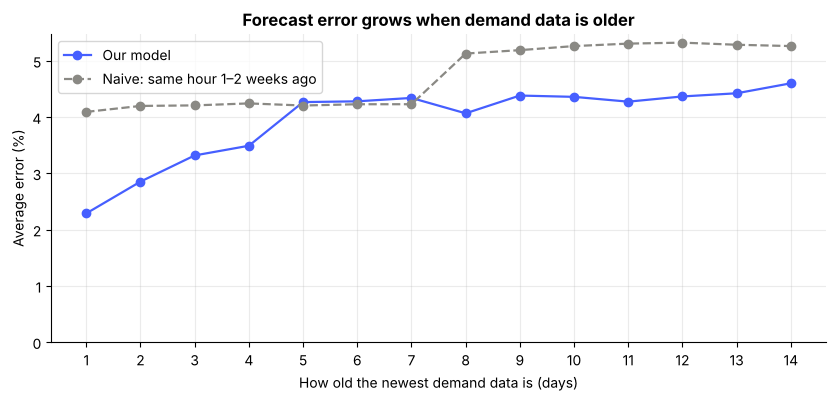

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(res.index, res["MAPE (%)"], marker="o", color=C["blue"], label="Our model")
ax.plot(res.index, res["Naive weekly MAE"] / res["MAE (MW)"] * res["MAPE (%)"], marker="o", color=C["grey"], ls="--",
        label="Naive: same hour 1–2 weeks ago")
ax.set_xlabel("How old the newest demand data is (days)"); ax.set_ylabel("Average error (%)")
ax.set_xticks(list(HORIZONS)); ax.set_ylim(0, None)
ax.set_title("Forecast error grows when demand data is older"); ax.legend(); plt.show()

###  How to read this
- With **yesterday's** data (horizon 1), the model is the most accurate — this is what the app achieves with a fresh daily feed.
- Error rises over the first few days, then levels off: beyond ~5 days the model relies mostly on **weekly patterns + weather**.
- Where the model doesn't beat the naive baseline by much (around days 5–7), forecasts are still usable, but the honest message is: **fresher data matters more than a fancier model.**

## 4.2 A close look at horizon 1 (fresh data)

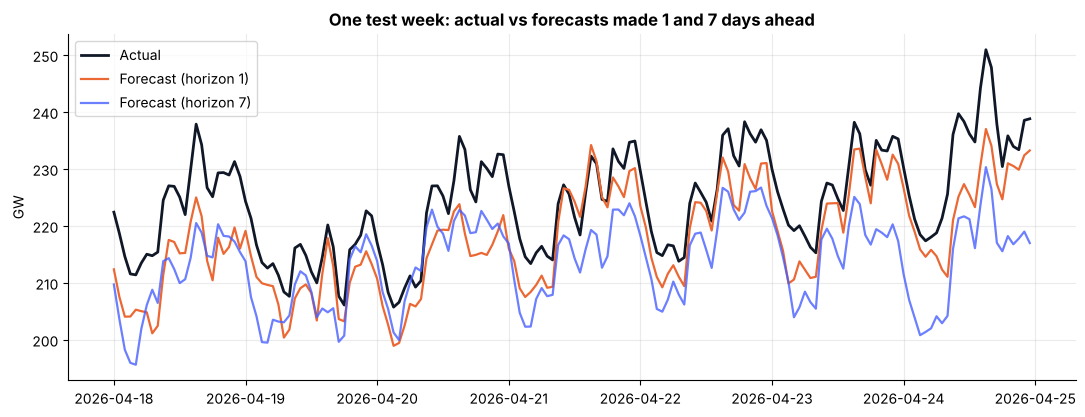

Top features (horizon 1):
is_weekend      0.337
day_of_week     0.137
hour            0.075
hour_cos        0.063
hour_sin        0.047
feels_change    0.041
doy_cos         0.025
feels_north     0.020
dtype: float32


In [10]:
y_all = data["demand"]
p1 = test_preds[1]
week = p1.index[(p1.index >= p1.index[0] + pd.Timedelta(days=200))][:24 * 7]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(week, y_all.loc[week] / 1000, color=C["ink"], lw=2, label="Actual")
ax.plot(week, p1.loc[week] / 1000, color=C["orange"], label="Forecast (horizon 1)")
ax.plot(week, test_preds[7].reindex(week) / 1000, color=C["blue"], alpha=0.8, label="Forecast (horizon 7)")
ax.set_ylabel("GW"); ax.set_title("One test week: actual vs forecasts made 1 and 7 days ahead"); ax.legend(); plt.show()

imp = pd.Series(backtest_models[1].feature_importances_, index=feature_names(1)).sort_values(ascending=False)
print("Top features (horizon 1):"); print(imp.head(8).round(3))

## 4.3 Does weather still help nationally?
Same check as Notebook 1: retrain horizons 1 and 7 **without** weather features and compare.

In [11]:
for h in [1, 7]:
    F = feature_names(h); Fnw = [f for f in F if f not in WEATHER_FEATURES + ["feels_change", "feels_change_wk"]]
    t = make_features(data, h)[F + ["demand"]].dropna(); tr, te = t[t.index < TEST_START], t[t.index >= TEST_START]
    m = make_model(h).fit(tr[Fnw], tr["demand"] - tr[base_col(h)])
    p = m.predict(te[Fnw]) + te[base_col(h)].values
    with_w = res.loc[h, "MAE (MW)"]; without = mean_absolute_error(te["demand"], p)
    print(f"Horizon {h}: MAE with weather {with_w:,.0f} MW | without {without:,.0f} MW → weather cuts error by {100 * (1 - with_w / without):.1f}%")

Horizon 1: MAE with weather 4,926 MW | without 6,609 MW → weather cuts error by 25.5%


Horizon 7: MAE with weather 9,302 MW | without 13,445 MW → weather cuts error by 30.8%


In [12]:
def forecast_day(history, day, models, threshold_mw=None):
    """Forecast the 24 hours of `day`.

    history : hourly DataFrame with 'demand' (NaN where unknown) and WEATHER_FEATURES
              (weather must exist for `day`, e.g. from a weather forecast).
    models  : dict {h: fitted model} for h = 1..14 (each predicts demand - base_col(h)).
    Uses horizon h = days between `day` and the last day with complete demand data.
    Returns (pd.Series of 24 forecasts in MW, info dict).
    """
    day = pd.Timestamp(day).normalize()
    hours = pd.date_range(day, periods=24, freq="h")
    known = history["demand"].loc[: day - pd.Timedelta(hours=1)].dropna()
    if known.empty:
        raise ValueError("No demand history before this date.")
    # last calendar day whose 24 hours of demand are all known
    counts = known.groupby(known.index.normalize()).size()
    full_days = counts[counts >= 23].index
    if len(full_days) == 0:
        raise ValueError("No complete day of demand data found.")
    last_full = full_days.max()
    h = int((day - last_full).days)
    if h < 1 or h not in models:
        raise ValueError(f"Date is {h} days after the newest complete demand data ({last_full.date()}); "
                         f"forecasts are available 1-{max(models)} days ahead.")

    window = pd.date_range(day - pd.Timedelta(days=40), hours[-1], freq="h")
    d = history.reindex(window)[["demand"] + WEATHER_FEATURES].copy()
    d.loc[d.index > last_full + pd.Timedelta(hours=23), "demand"] = np.nan   # never peek past last_full
    X = make_features(d, h).loc[hours, feature_names(h)]
    if X[WEATHER_FEATURES].isna().any().any():
        raise ValueError(f"Weather data missing for {day.date()}.")
    if X.isna().any().any():
        bad = X.columns[X.isna().any()].tolist()
        raise ValueError(f"Not enough continuous demand history before {day.date()} (missing: {bad}).")
    pred = models[h].predict(X) + X[base_col(h)].values
    return pd.Series(pred, index=hours, name="forecast_MW"), {"horizon_days": h, "last_demand_date": str(last_full.date())}


def rolling_threshold(demand, day, quantile=0.99, window_days=365, min_days=90):
    """Grid limit for `day` = the top-1% demand level of the past year (known data only).
    Keeps up with demand growth. Returns None if there isn't enough history."""
    day = pd.Timestamp(day).normalize()
    past = demand.loc[day - pd.Timedelta(days=window_days): day - pd.Timedelta(hours=1)].dropna()
    if len(past) < 24 * min_days:
        return None
    return float(past.quantile(quantile))

# PART 5 — National grid limit & optimiser check

**A fixed limit doesn't work nationally.** India's demand grows ~5%+ per year (2026 set a record of ~270 GW), so a limit taken from 2024–25 data would be crossed thousands of hours a year — then "peak" means nothing.

So the limit is **rolling**: for each day, *the top-1% demand level of the previous 365 days*. It moves up as demand grows, and flags hours that are unusually high **for the current level of demand**. (An authority would replace this with its real capacity figure in the app settings.)

Then we run the optimiser (from Notebook 2, `peak_optimizer.py`) on **every test day** using the horizon-1 forecasts, apply each plan to the **actual** demand, and measure how much over-limit energy it would have avoided. Safety margin ≈ the horizon-1 average error.

In [13]:
from peak_optimizer import optimize_day, apply_plan_to_actual

MARGIN = float(round(res.loc[1, "MAE (MW)"] / 500) * 500)
FLEX = 0.10
THRESHOLD = rolling_threshold(y_all, TEST_START)      # limit at the start of the test year (for reference)
print(f"Rolling grid limit on {TEST_START.date()}: {THRESHOLD:,.0f} MW | safety margin: {MARGIN:,.0f} MW | flexible share: {FLEX:.0%}")

over_b = over_a = 0.0; hours_b = hours_a = acted = 0
fc = test_preds[1]
for day, grp in fc.groupby(fc.index.normalize()):
    if len(grp) != 24: continue
    act = y_all.reindex(grp.index).values
    if np.isnan(act).any(): continue
    thr = rolling_threshold(y_all, day)                # this day's limit, from the past year only
    plan = optimize_day(grp.values, thr, flex_share=FLEX, max_shift_hours=3, safety_margin_mw=MARGIN)
    after = apply_plan_to_actual(act, plan)
    over_b += np.clip(act - thr, 0, None).sum(); over_a += np.clip(after - thr, 0, None).sum()
    hours_b += int((act > thr).sum()); hours_a += int((after > thr + 1).sum())
    acted += plan["summary"]["energy_shifted_MWh"] > 0
print(f"Days the system acted: {acted}")
print(f"Actual energy above the limit: {over_b/1000:,.0f} → {over_a/1000:,.0f} GWh ({100*(1-over_a/max(over_b,1)):.1f}% less)")
print(f"Actual hours above the limit:  {hours_b} → {hours_a}")

Rolling grid limit on 2025-09-30: 230,959 MW | safety margin: 5,000 MW | flexible share: 10%


Days the system acted: 114
Actual energy above the limit: 2,280 → 1,227 GWh (46.2% less)
Actual hours above the limit:  396 → 330


# PART 6 — Save everything for the backend

1. **Backtest models** (trained before the test year) → used by the app for test-year dates, so replay shows honest accuracy.
2. **Production models** (retrained on **all** data) → used for live forecasts of today and future days.
3. `national_history.csv` → hourly demand + aggregated weather (the backend's starting data).
4. `national_config.json` → horizons, metrics, grid limit, cities, test period.
5. `grid_forecast.py` → the shared functions above.

In [14]:
os.makedirs(f"{OUT_DIR}/backtest", exist_ok=True); os.makedirs(f"{OUT_DIR}/production", exist_ok=True)
t0 = time.time()
for h in HORIZONS:
    joblib.dump(backtest_models[h], f"{OUT_DIR}/backtest/h{h}.pkl")
    F = feature_names(h); t = make_features(data, h)[F + ["demand"]].dropna()
    joblib.dump(make_model(h).fit(t[F], t["demand"] - t[base_col(h)]), f"{OUT_DIR}/production/h{h}.pkl")
print(f"Saved 28 models in {time.time() - t0:.0f} s")

full_hist = weather.join(demand.rename("demand"), how="left")    # keep weather beyond the last demand hour
full_hist[["demand"] + WEATHER_FEATURES].round(2).to_csv(f"{OUT_DIR}/national_history.csv", index_label="datetime")

config = {
    "region": "All-India", "unit": "MW",
    "horizons": list(HORIZONS),
    "cities": CITY_GROUPS,
    "test_period": {"start": str(TEST_START.date()), "end": str(last.date())},
    "test_metrics": {str(h): {"MAE_MW": round(r["MAE (MW)"], 1), "RMSE_MW": round(r["RMSE (MW)"], 1),
                              "R2": round(r["R²"], 4), "MAPE_pct": round(r["MAPE (%)"], 2)} for h, r in res.iterrows()},
    "peak_detection": {"mode": "rolling", "quantile": 0.99, "window_days": 365, "warning_ratio": 0.95,
                       "threshold_rule": "99th percentile of national demand over the 365 days before each date",
                       "reference_threshold_mw": round(THRESHOLD, 1)},
    "optimizer_defaults": {"flex_share": FLEX, "max_shift_hours": 3, "safety_margin_mw": MARGIN, "curtail_share": 0.02},
    "data_sources": {"demand_new": NEW_DEMAND_URL, "weather": "ERA5 / Open-Meteo, 11 cities"},
    "last_demand_hour": str(last), "weather_until": str(weather.index.max()),
    "versions": {"pandas": pd.__version__, "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__},
}
json.dump(config, open(f"{OUT_DIR}/national_config.json", "w"), indent=2)
print("Saved national_history.csv and national_config.json")

Saved 28 models in 18 s


Saved national_history.csv and national_config.json


In [15]:
%%writefile grid_forecast.py
"""
grid_forecast.py
================
All-India electricity demand forecasting: weather aggregation, multi-horizon features,
and forecasting for any day 1-7 days after the newest demand data.

Used by BOTH the training notebook and the FastAPI backend, so features are always
computed the same way.  Dependencies: numpy, pandas.
"""
import numpy as np
import pandas as pd

# 11 cities, grouped by grid region. National demand reacts to heat in every region.
CITY_GROUPS = {
    "north": ["delhi", "lucknow", "jaipur", "chandigarh", "ludhiana"],
    "west": ["mumbai", "ahmedabad"],
    "south": ["chennai", "bengaluru", "hyderabad"],
    "east": ["kolkata"],
}
CITIES = [c for group in CITY_GROUPS.values() for c in group]
CDH_BASE, HDH_BASE = 24.0, 18.0


def aggregate_weather(long_df):
    """Turn per-city hourly weather (long format, Open-Meteo column names) into one
    row per hour with national averages + regional 'feels like' temperatures."""
    w = long_df.rename(columns={"temperature_2m": "temperature", "relative_humidity_2m": "humidity",
                                "apparent_temperature": "feels_like", "precipitation": "rain_mm"}).copy()
    w["datetime"] = pd.to_datetime(w["datetime"], format="ISO8601")
    w = w[w["city"].isin(CITIES)]
    w["cdh_city"] = (w["feels_like"] - CDH_BASE).clip(lower=0)     # cooling need per city
    w["hdh_city"] = (HDH_BASE - w["temperature"]).clip(lower=0)    # heating need per city

    nat = w.groupby("datetime")[["temperature", "humidity", "feels_like", "rain_mm", "cdh_city", "hdh_city"]].mean()
    nat.columns = ["nat_temp", "nat_humidity", "nat_feels", "nat_rain", "nat_cdh", "nat_hdh"]
    for region, cities in CITY_GROUPS.items():
        nat[f"feels_{region}"] = w[w["city"].isin(cities)].groupby("datetime")["feels_like"].mean()
    complete = w.groupby("datetime")["city"].nunique() == len(CITIES)  # only hours with all 11 cities
    return nat[complete.reindex(nat.index, fill_value=False)]


WEATHER_FEATURES = ["nat_temp", "nat_humidity", "nat_feels", "nat_rain", "nat_cdh", "nat_hdh",
                    "feels_north", "feels_west", "feels_south", "feels_east"]

SEASON_MAP = {12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1, 6: 2, 7: 2, 8: 2, 9: 2, 10: 3, 11: 3}
CALENDAR_FEATURES = ["hour", "day_of_week", "month", "is_weekend", "season",
                     "hour_sin", "hour_cos", "doy_sin", "doy_cos"]
HORIZONS = range(1, 15)         # 1 to 14 days after the newest demand data


def week_lag(h):
    """Smallest whole number of weeks (in hours) that is at least h days back."""
    return 168 * int(np.ceil(h / 7))


def lag_hours(h):
    """Demand lags allowed for horizon h: nothing newer than h*24 hours before the target hour."""
    L, wk = 24 * h, week_lag(h)
    return sorted({L, L + 24, wk, wk + 168})


def base_col(h):
    """The model predicts the CHANGE from this lag (1 day ahead: yesterday; otherwise same weekday)."""
    return "lag_24" if h == 1 else f"lag_{week_lag(h)}"


def model_params(h):
    """Short horizons: a deeper model. Longer horizons: a simpler model that overfits less."""
    if h <= 2:
        return dict(n_estimators=600, learning_rate=0.05, max_depth=6, min_child_weight=1)
    return dict(n_estimators=200, learning_rate=0.05, max_depth=3, min_child_weight=50)


def feature_names(h):
    return CALENDAR_FEATURES + WEATHER_FEATURES + ["feels_change", "feels_change_wk",
            "roll_mean_24", "roll_max_24", "roll_mean_168"] + [f"lag_{k}" for k in lag_hours(h)]


def make_features(d, h):
    """d: hourly DataFrame (datetime index) with 'demand' + WEATHER_FEATURES.
    Returns d with every feature for horizon h. Nothing uses demand newer than t - 24h."""
    d = d.copy()
    idx = d.index
    L, wk = 24 * h, week_lag(h)
    d["hour"] = idx.hour
    d["day_of_week"] = idx.dayofweek
    d["month"] = idx.month
    d["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    d["season"] = d["month"].map(SEASON_MAP)
    d["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    d["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    d["doy_sin"] = np.sin(2 * np.pi * idx.dayofyear / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * idx.dayofyear / 365.25)

    for k in lag_hours(h):
        d[f"lag_{k}"] = d["demand"].shift(k)
    past = d["demand"].shift(L)                       # newest demand value we may use
    d["roll_mean_24"] = past.rolling(24).mean()
    d["roll_max_24"] = past.rolling(24).max()
    d["roll_mean_168"] = past.rolling(168).mean()
    d["feels_change"] = d["nat_feels"] - d["nat_feels"].shift(L)       # hotter/colder than then?
    d["feels_change_wk"] = d["nat_feels"] - d["nat_feels"].shift(wk)
    return d

def forecast_day(history, day, models, threshold_mw=None):
    """Forecast the 24 hours of `day`.

    history : hourly DataFrame with 'demand' (NaN where unknown) and WEATHER_FEATURES
              (weather must exist for `day`, e.g. from a weather forecast).
    models  : dict {h: fitted model} for h = 1..14 (each predicts demand - base_col(h)).
    Uses horizon h = days between `day` and the last day with complete demand data.
    Returns (pd.Series of 24 forecasts in MW, info dict).
    """
    day = pd.Timestamp(day).normalize()
    hours = pd.date_range(day, periods=24, freq="h")
    known = history["demand"].loc[: day - pd.Timedelta(hours=1)].dropna()
    if known.empty:
        raise ValueError("No demand history before this date.")
    # last calendar day whose 24 hours of demand are all known
    counts = known.groupby(known.index.normalize()).size()
    full_days = counts[counts >= 23].index
    if len(full_days) == 0:
        raise ValueError("No complete day of demand data found.")
    last_full = full_days.max()
    h = int((day - last_full).days)
    if h < 1 or h not in models:
        raise ValueError(f"Date is {h} days after the newest complete demand data ({last_full.date()}); "
                         f"forecasts are available 1-{max(models)} days ahead.")

    window = pd.date_range(day - pd.Timedelta(days=40), hours[-1], freq="h")
    d = history.reindex(window)[["demand"] + WEATHER_FEATURES].copy()
    d.loc[d.index > last_full + pd.Timedelta(hours=23), "demand"] = np.nan   # never peek past last_full
    X = make_features(d, h).loc[hours, feature_names(h)]
    if X[WEATHER_FEATURES].isna().any().any():
        raise ValueError(f"Weather data missing for {day.date()}.")
    if X.isna().any().any():
        bad = X.columns[X.isna().any()].tolist()
        raise ValueError(f"Not enough continuous demand history before {day.date()} (missing: {bad}).")
    pred = models[h].predict(X) + X[base_col(h)].values
    return pd.Series(pred, index=hours, name="forecast_MW"), {"horizon_days": h, "last_demand_date": str(last_full.date())}


def rolling_threshold(demand, day, quantile=0.99, window_days=365, min_days=90):
    """Grid limit for `day` = the top-1% demand level of the past year (known data only).
    Keeps up with demand growth. Returns None if there isn't enough history."""
    day = pd.Timestamp(day).normalize()
    past = demand.loc[day - pd.Timedelta(days=window_days): day - pd.Timedelta(hours=1)].dropna()
    if len(past) < 24 * min_days:
        return None
    return float(past.quantile(quantile))

Overwriting grid_forecast.py


## 6.1 Quick test: forecast the day after the newest data

Exactly what the backend will do: give the history (with demand ending at `last`) plus weather for the next day, and let `forecast_day()` pick the right model automatically.

In [16]:
prod = {h: joblib.load(f"{OUT_DIR}/production/h{h}.pkl") for h in HORIZONS}
full = weather.join(demand.rename("demand"), how="left")     # weather goes further than demand
next_day = last.normalize() + pd.Timedelta(days=1)
if next_day + pd.Timedelta(hours=23) <= weather.index.max():
    fc_next, info = forecast_day(full, next_day, prod)
    THR_NEXT = rolling_threshold(full["demand"], next_day)
    print(f"Forecast for {next_day.date()} using horizon-{info['horizon_days']} model (newest demand: {info['last_demand_date']})")
    print(f"Peak {fc_next.max()/1000:.1f} GW at {fc_next.idxmax():%H:%M} | rolling limit {THR_NEXT/1000:.1f} GW")
else:
    print("No weather for the next day in the file — the backend fetches a live weather forecast for this.")

Forecast for 2026-09-30 using horizon-1 model (newest demand: 2026-09-29)
Peak 236.9 GW at 15:00 | rolling limit 256.6 GW


#  Summary

**Data.** All-India hourly demand, Jan 2019 → Sep 2026, from two sources that join smoothly (December daily shapes correlate 0.997, growth continues without a jump). Weather from 11 cities in 4 regions.

**Accuracy on the unseen test year (Sep 2025 → Sep 2026)** *(your run may differ in the last digits)*:

| Newest demand data is… | Average error | R² |
|---|---|---|
| 1 day old | **4.9 GW (2.3%)** | 0.946 |
| 2–4 days old | 6.0–7.3 GW (2.9–3.5%) | 0.88–0.92 |
| 5–14 days old | 8.6–9.8 GW (4.1–4.6%) | 0.79–0.84 |

- Horizons 1–4 clearly beat the naive "same hour last week"; around 5–7 days the model is roughly as good as naive, and 8–14 days clearly better than "same hour two weeks ago". **Fresh data is what matters most.**
- **Weather matters nationally too:** it cuts error by ~25% (1 day ahead) and ~31% (7 days ahead).
- **Rolling grid limit** (top 1% of the past year): the optimiser would have avoided **~46% of over-limit energy** in the test year (10% flexible load, 3 h max shift, 5 GW safety margin).

**Saved for the backend** (`national/`): 14 backtest + 14 production models, `national_history.csv`, `national_config.json`, and `grid_forecast.py`.

**Honest limits:** no holiday calendar yet (Diwali etc. cause dips the model can't foresee); the May–Oct 2024 gap; the 2026 test year had record growth, which makes it a tough (and therefore honest) test.